In [1]:
import warnings

import matplotlib.pyplot as plt

from utils.results import load_results, select, summary_table
from utils.plots import (coverage_heatmap, pairwise_scatter,
                         performance_profile, scaling_plot)

warnings.simplefilter('always', UserWarning)
plt.rcParams['figure.dpi'] = 110

SOURCE = 'aws-B-S.xlsx'
df = load_results(SOURCE)

FORMULATIONS = select(df, base=['ABF', 'PBF'], decomposition=True)
LABELS = None
TIME_SCALE = 'log'

FORMULATIONS

['ABF-D-S-B',
 'ABF-A-D-S-B',
 'PBF-D-enum-S-B',
 'PBF-D-dual-S-OC-B',
 'PBF-A-D-enum-S-B',
 'PBF-A-D-dual-S-OC-B']

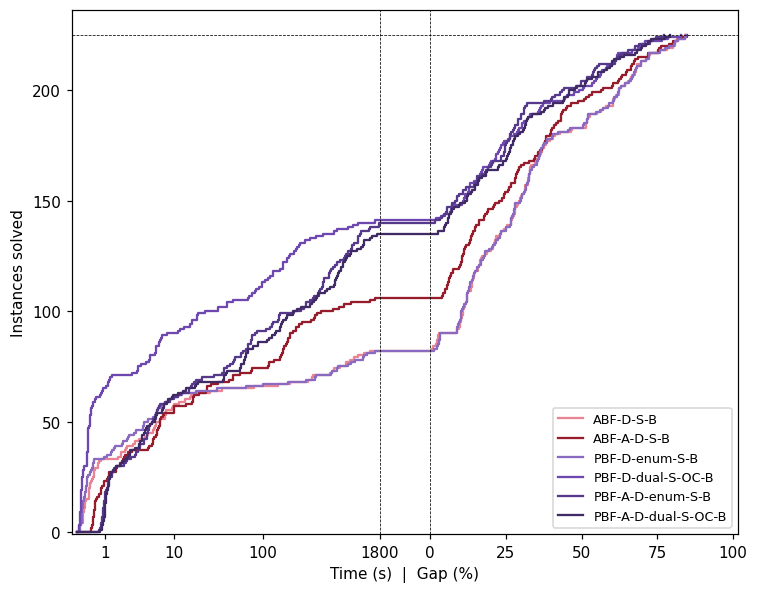

In [2]:
performance_profile(df, FORMULATIONS, labels=LABELS, time_scale=TIME_SCALE,
                    figsize=(7, 5.5))

In [3]:
summary_table(df, FORMULATIONS, labels=LABELS)

,Formulation,Runs,Opt,TimeOpt,Gap (%),Gap NoOpt (%),Cuts
0,ABF-D-S-B,225,82,135.03,22.25,35.01,33448.25
1,ABF-A-D-S-B,225,106,115.06,18.30,34.59,115.83
2,PBF-D-enum-S-B,225,82,146.11,22.23,34.97,33299.42
3,PBF-D-dual-S-OC-B,225,141,80.44,12.89,34.54,1182.14
4,PBF-A-D-enum-S-B,225,140,224.95,12.35,32.70,142.08
5,PBF-A-D-dual-S-OC-B,225,135,217.13,13.42,33.55,98.61


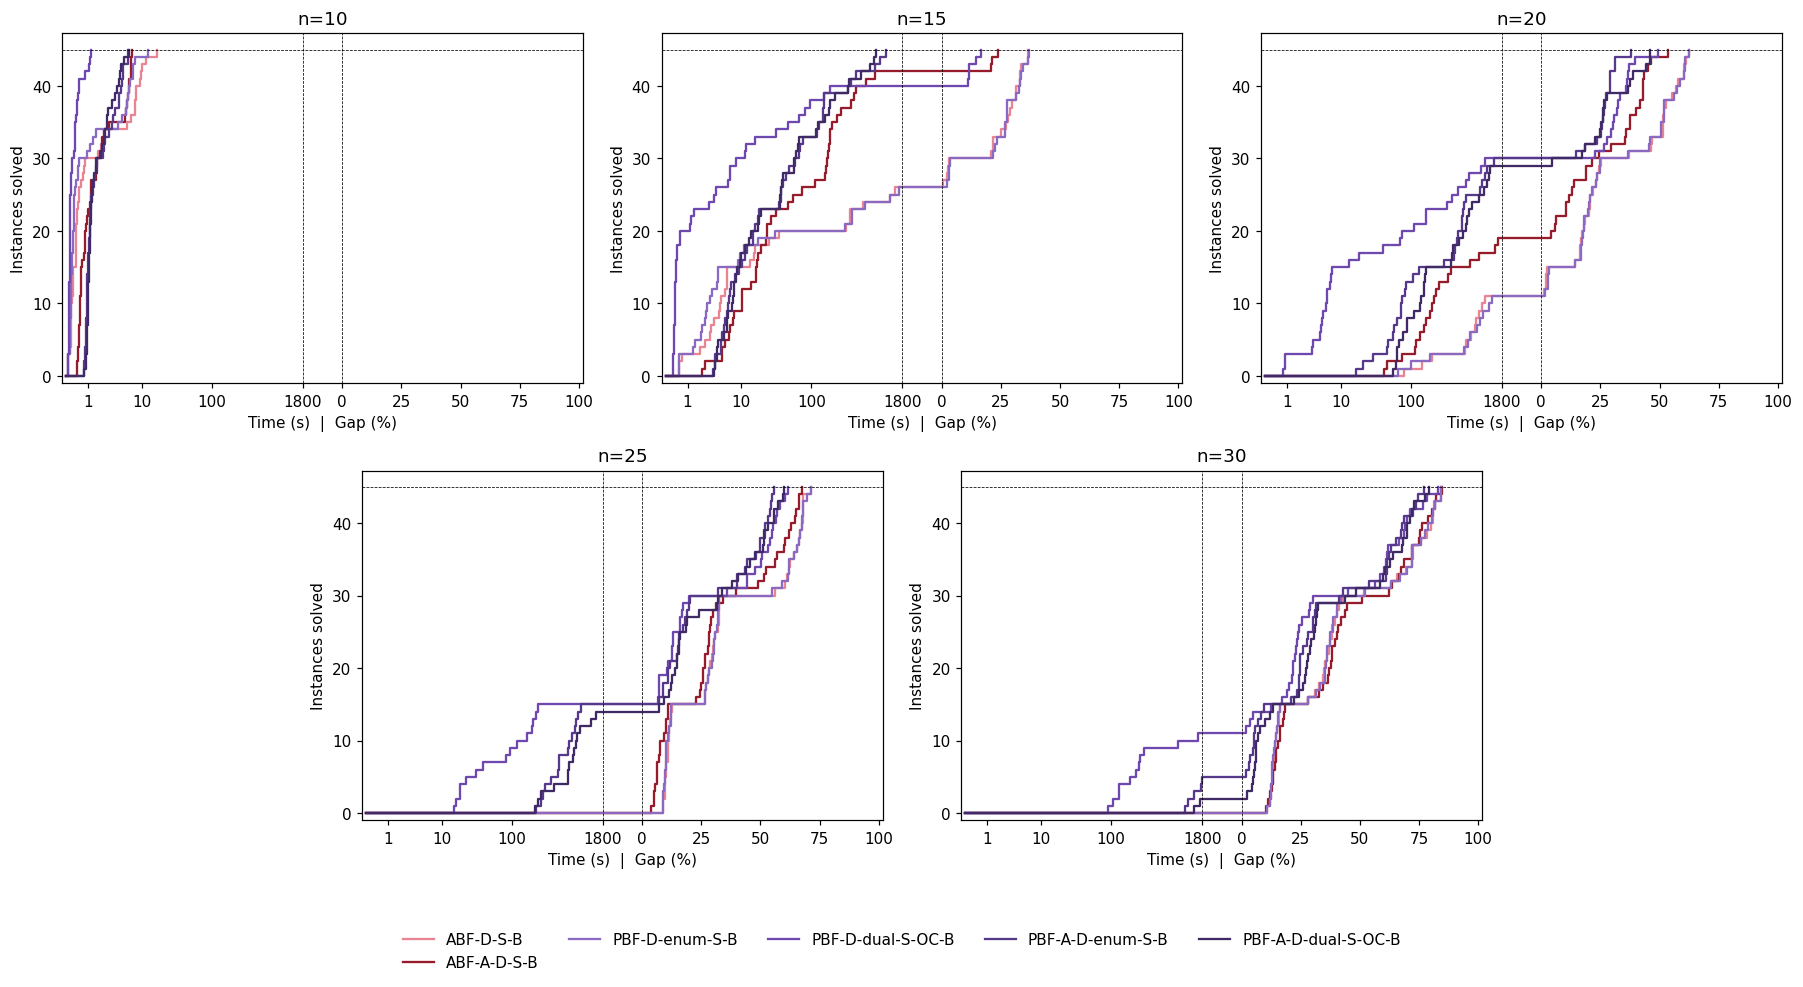

In [4]:
performance_profile(df, FORMULATIONS, labels=LABELS, time_scale=TIME_SCALE,
                    facet_by='n')

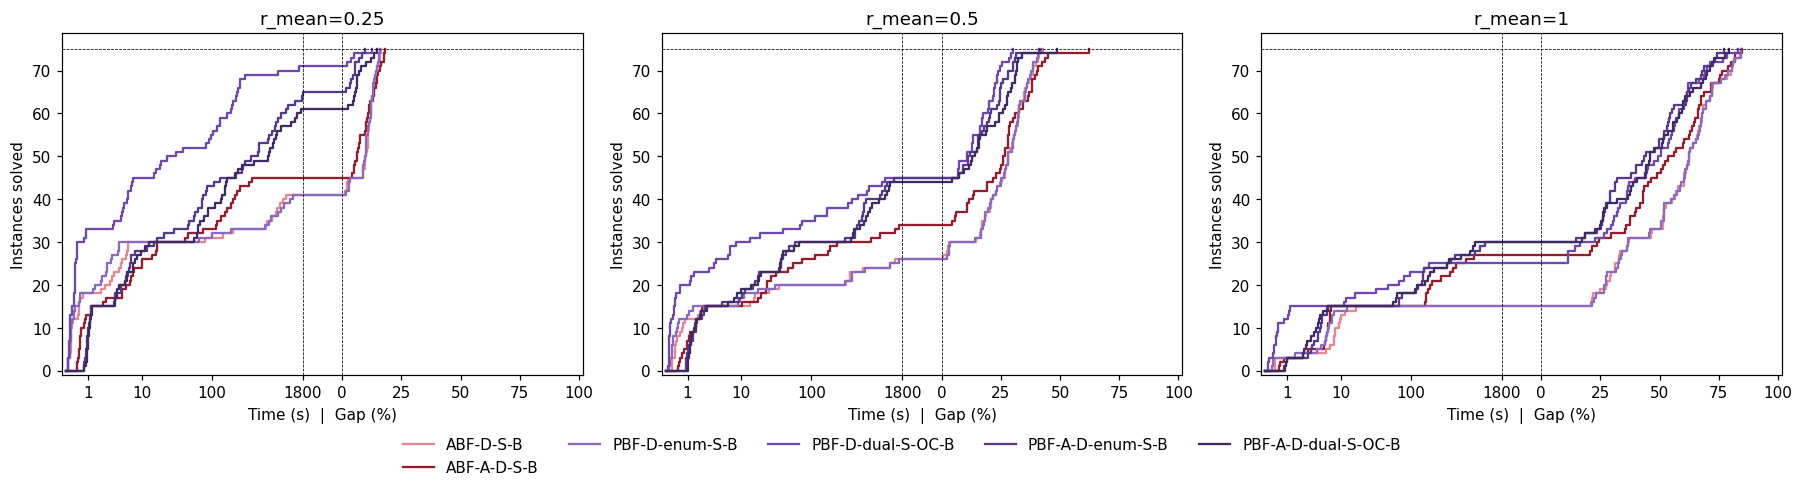

In [5]:
performance_profile(df, FORMULATIONS, labels=LABELS, time_scale=TIME_SCALE,
                    facet_by='r_mean')

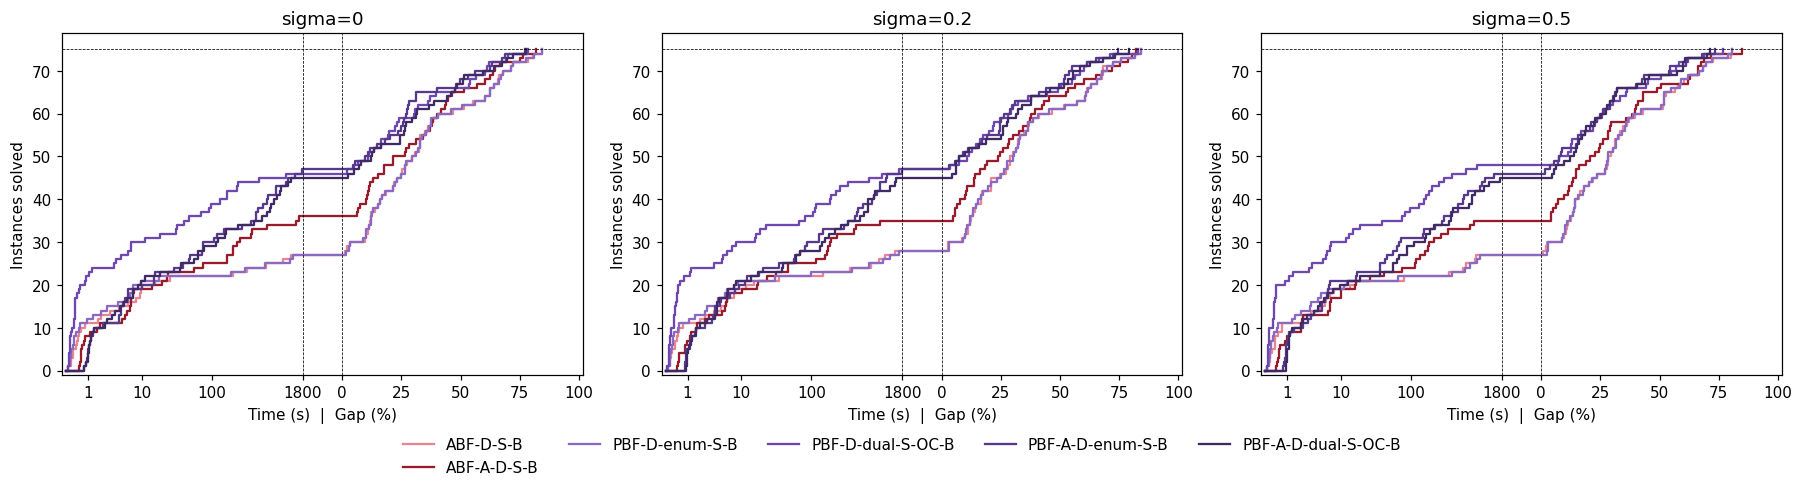

In [6]:
performance_profile(df, FORMULATIONS, labels=LABELS, time_scale=TIME_SCALE,
                    facet_by='sigma')

In [7]:
summary_table(df, FORMULATIONS, labels=LABELS, by='n',
              metrics=('Runs', 'Opt', 'TimeOpt', 'Gap (%)', 'RootGap (%)'))

,Formulation,n,Runs,Opt,TimeOpt,Gap (%),RootGap (%)
0,ABF-D-S-B,10,45,45,2.68,0.00,20.37
1,ABF-D-S-B,15,45,26,165.84,9.91,31.92
2,ABF-D-S-B,20,45,11,603.67,24.64,36.98
3,ABF-D-S-B,25,45,0,-,35.20,41.15
4,ABF-D-S-B,30,45,0,-,41.51,45.96
5,ABF-A-D-S-B,10,45,45,2.19,-0.00,36.39
6,ABF-A-D-S-B,15,45,42,117.59,1.45,44.69
7,ABF-A-D-S-B,20,45,19,376.80,16.32,52.39
8,ABF-A-D-S-B,25,45,0,-,31.28,57.28
9,ABF-A-D-S-B,30,45,0,-,42.43,62.52


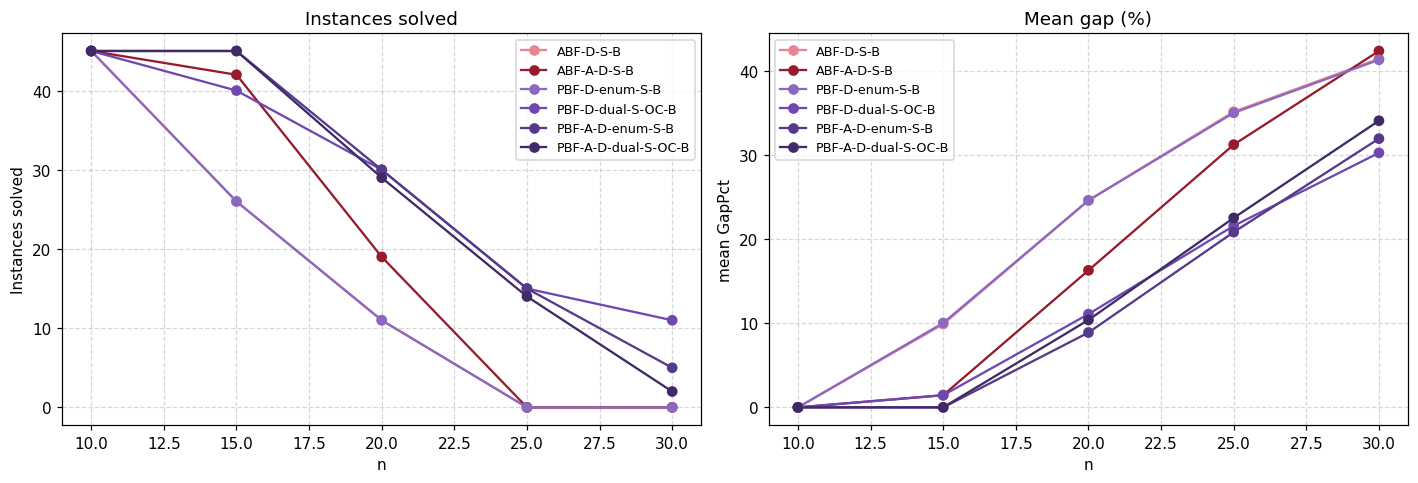

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
scaling_plot(df, FORMULATIONS, labels=LABELS, agg='solved', over='n',
             ax=axes[0], title='Instances solved')
scaling_plot(df, FORMULATIONS, labels=LABELS, metric='GapPct', agg='mean',
             over='n', ax=axes[1], title='Mean gap (%)')
fig.tight_layout()

c:\Users\daray\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\interactiveshell.py:3460: UserWarning: line(s) stop short because a formulation solved nothing there: ABF-D-S-B at n=25, 30; ABF-A-D-S-B at n=25, 30; PBF-D-enum-S-B at n=25, 30.  Those points are gaps, not zeros.
  exec(code_obj, self.user_global_ns, self.user_ns)


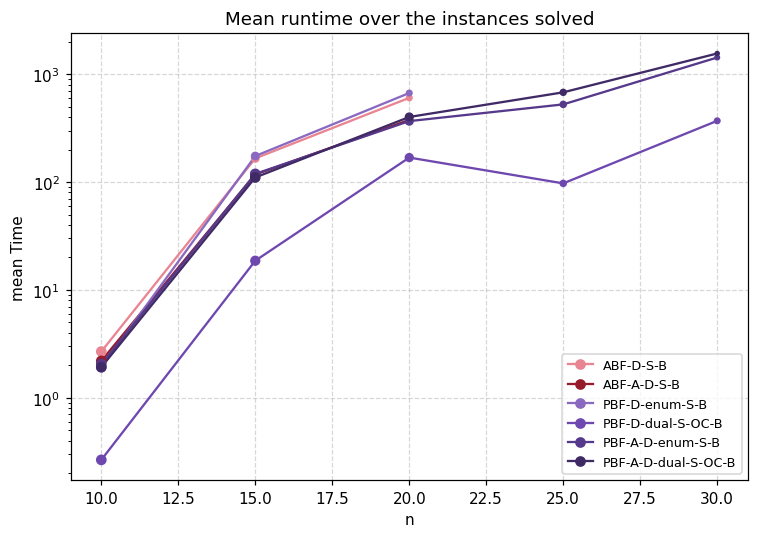

In [9]:
scaling_plot(df, FORMULATIONS, labels=LABELS, metric='Time', agg='mean',
             over='n', solved_only=True, logy=True,
             title='Mean runtime over the instances solved')

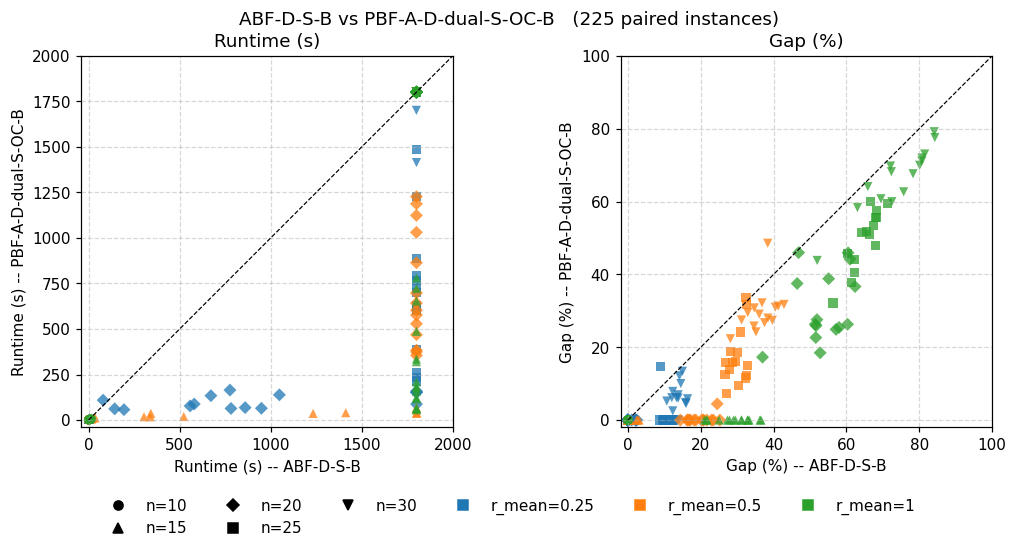

In [10]:
pairwise_scatter(df, FORMULATIONS[0], FORMULATIONS[-1],
                 metrics=('Time', 'GapPct'), color_by='r_mean', marker_by='n')

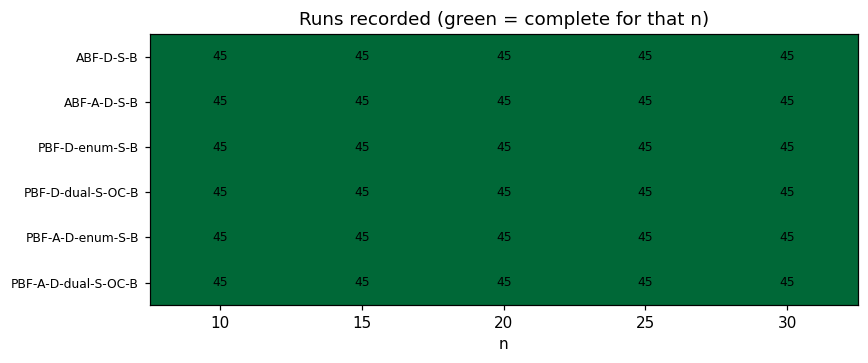

In [11]:
coverage_heatmap(df, FORMULATIONS, over='n')